# Criteo Uplift Modeling

Задача — найти пользователей, на которых реклама действительно влияет, а не тех, кто совершит целевое действие и без неё.

Данные: Criteo Uplift Prediction Dataset (Diemert et al., AdKDD 2018). ~25M строк, 12 признаков, бинарный treatment, метрика — visit.

Подход: сначала baseline A/B-тест, затем uplift-модель (S-learner на CatBoost), затем оценка через Qini AUC и децильный анализ.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

from sklift.models import SoloModel, TwoModels
from sklift.metrics import qini_auc_score, uplift_auc_score, uplift_at_k, uplift_curve, qini_curve

RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
%matplotlib inline

## Данные

In [2]:
DATA_PATH = Path('data/criteo-uplift-v2.1.csv')

dtypes = {f'f{i}': 'float32' for i in range(12)}
dtypes.update({'treatment': 'int8', 'visit': 'int8', 'conversion': 'int8', 'exposure': 'int8'})

chunks = []
for i, ch in enumerate(pd.read_csv(DATA_PATH, dtype=dtypes, chunksize=2_000_000)):
    chunks.append(ch.sample(frac=0.20, random_state=42 + i))

df = pd.concat(chunks, ignore_index=True)
del chunks

print(f"Shape: {df.shape}")
print(f"Treatment ratio: {df['treatment'].mean():.4f}")
print(f"\nVisit rate by group:\n{df.groupby('treatment')['visit'].mean()}")
print(f"\nConversion rate by group:\n{df.groupby('treatment')['conversion'].mean()}")

Shape: (2795918, 16)
Treatment ratio: 0.8499

Visit rate by group:
treatment
0    0.038378
1    0.048340
Name: visit, dtype: float64

Conversion rate by group:
treatment
0    0.001923
1    0.003107
Name: conversion, dtype: float64


In [3]:
observed = df['treatment'].value_counts().sort_index().values
expected = np.array([0.15, 0.85]) * len(df)
chi2, p_srm = chisquare(observed, expected)
print(f"Наблюдаемое распределение: control={observed[0]:,}, treatment={observed[1]:,}")
print(f"Ожидаемое (85/15): control={expected[0]:,.0f}, treatment={expected[1]:,.0f}")
print(f"p-value теста SRM: {p_srm:.4f}")

Наблюдаемое распределение: control=419,742, treatment=2,376,176
Ожидаемое (85/15): control=419,388, treatment=2,376,530
p-value теста SRM: 0.5529


## Baseline A/B

Two-proportion z-test на visit. Это уровень, с которым сравниваю uplift-модель.

In [4]:
control = df.loc[df['treatment'] == 0, 'visit']
treatment = df.loc[df['treatment'] == 1, 'visit']

n_ctrl, n_treat = len(control), len(treatment)
p_ctrl, p_treat = control.mean(), treatment.mean()

abs_uplift = p_treat - p_ctrl
rel_uplift = abs_uplift / p_ctrl

count = np.array([treatment.sum(), control.sum()])
nobs = np.array([n_treat, n_ctrl])
zstat, p_value = proportions_ztest(count, nobs, alternative='two-sided')

ci_ctrl = proportion_confint(control.sum(), n_ctrl, method='wilson')
ci_treat = proportion_confint(treatment.sum(), n_treat, method='wilson')

print(f"Конверсия в visit (control):   {p_ctrl:.4%}   95% ДИ: [{ci_ctrl[0]:.4%}, {ci_ctrl[1]:.4%}]")
print(f"Конверсия в visit (treatment): {p_treat:.4%}   95% ДИ: [{ci_treat[0]:.4%}, {ci_treat[1]:.4%}]")
print()
print(f"Абсолютный uplift:  {abs_uplift:.4%} ({abs_uplift*100:.3f} п.п.)")
print(f"Относительный uplift: {rel_uplift:.2%}")
print()
print(f"Z-статистика: {zstat:.2f}")
print(f"p-value: {p_value:.2e}")

Конверсия в visit (control):   3.8378%   95% ДИ: [3.7801%, 3.8964%]
Конверсия в visit (treatment): 4.8340%   95% ДИ: [4.8068%, 4.8614%]

Абсолютный uplift:  0.9962% (0.996 п.п.)
Относительный uplift: 25.96%

Z-статистика: 28.16
p-value: 1.92e-174


## Uplift-модель

S-learner: treatment как признак, таргет — visit. Uplift = разница предсказаний при treatment=1 и treatment=0.

CatBoost, 300 итераций, depth=6. Train/val 80/20, стратификация по treatment.

In [5]:
X = df[[f'f{i}' for i in range(12)]]
y = df['visit']
treat = df['treatment']

X_train, X_val, y_train, y_val, treat_train, treat_val = train_test_split(
    X, y, treat,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=treat
)

print(f"Обучающая выборка:     {X_train.shape}")
print(f"Валидационная выборка: {X_val.shape}")

Обучающая выборка:     (2236734, 12)
Валидационная выборка: (559184, 12)


In [6]:
sm = SoloModel(
    CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_state=RANDOM_STATE,
        thread_count=-1
    )
)

sm = sm.fit(X_train, y_train, treat_train)
uplift_sm = sm.predict(X_val)

print(f"Uplift предсказания: mean={uplift_sm.mean():.6f}, std={uplift_sm.std():.6f}")
print(f"Минимум: {uplift_sm.min():.6f}, максимум: {uplift_sm.max():.6f}")

Uplift предсказания: mean=0.006476, std=0.018561
Минимум: -0.041140, максимум: 0.288457


## Метрики

Uplift@30% — средний uplift в топ-30% предсказанных.
Qini AUC — качество ранжирования по uplift.
Uplift AUC — альтернативная метрика, проверяю для устойчивости.

In [7]:
u30 = uplift_at_k(y_val, uplift_sm, treat_val, k=0.3, strategy='overall')
qini = qini_auc_score(y_val, uplift_sm, treat_val)
auuc = uplift_auc_score(y_val, uplift_sm, treat_val)

print(f"Uplift@30%:     {u30:.6f}")
print(f"Qini AUC:       {qini:.6f}")
print(f"Uplift AUC:     {auuc:.6f}")

Uplift@30%:     0.028629
Qini AUC:       0.093391
Uplift AUC:     0.036686


## Графики

Qini-кривая, uplift-кривая и uplift по децилям предсказания.

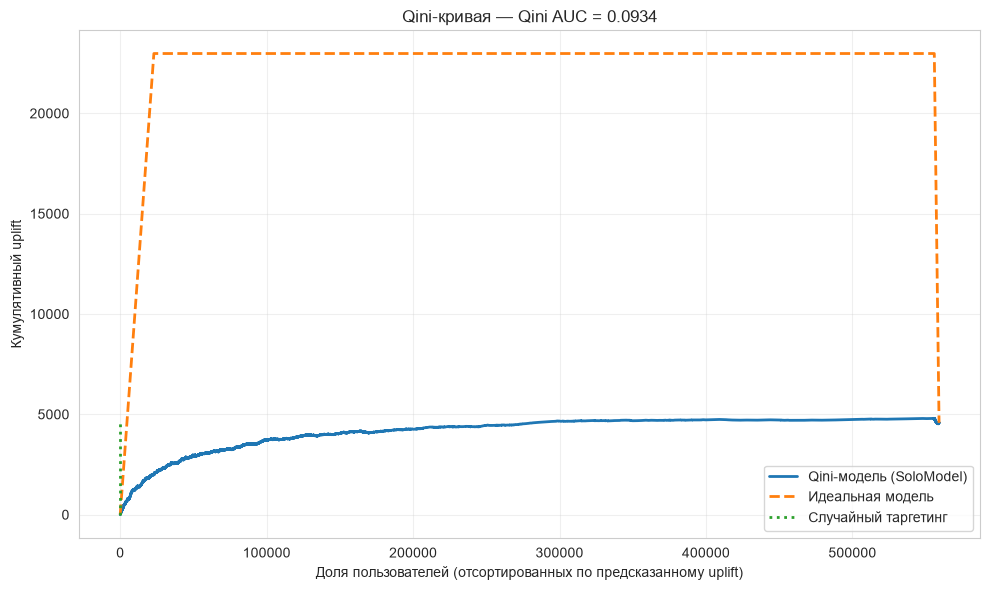

In [8]:
from sklift.metrics import qini_curve, perfect_qini_curve

x_qini, y_qini = qini_curve(y_val, uplift_sm, treat_val)
x_perf, y_perf = perfect_qini_curve(y_val, treat_val)
x_rand = np.linspace(0, 1, 100)
y_rand = np.linspace(0, y_qini[-1], 100)

plt.figure(figsize=(10, 6))
plt.plot(x_qini, y_qini, label='Qini-модель (SoloModel)', linewidth=2)
plt.plot(x_perf, y_perf, label='Идеальная модель', linestyle='--', linewidth=2)
plt.plot(x_rand, y_rand, label='Случайный таргетинг', linestyle=':', linewidth=2)
plt.xlabel('Доля пользователей (отсортированных по предсказанному uplift)')
plt.ylabel('Кумулятивный uplift')
plt.title(f'Qini-кривая — Qini AUC = {qini:.4f}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('assets/qini_curve.png', dpi=150, bbox_inches='tight')
plt.show()

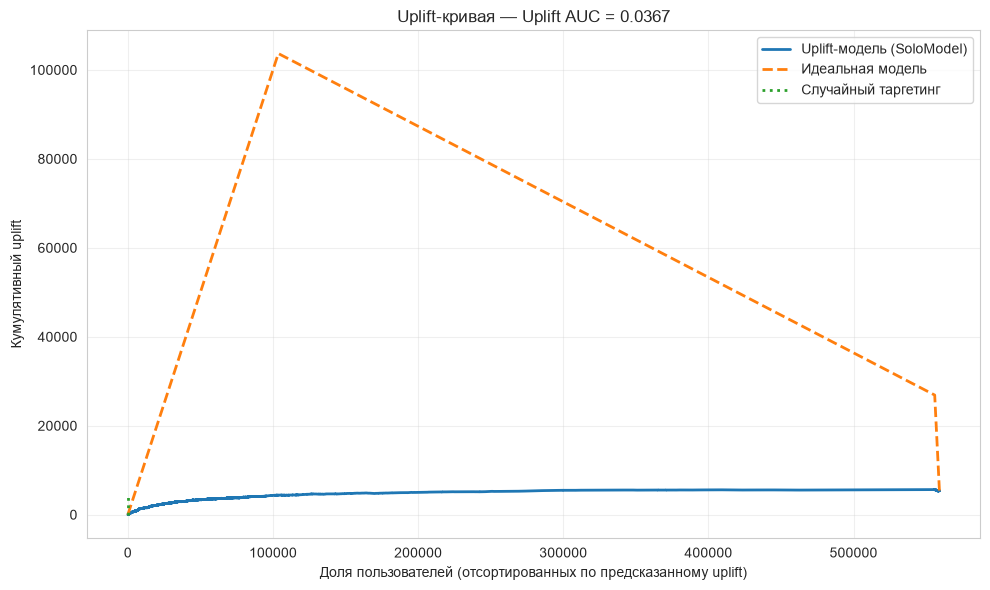

In [9]:
from sklift.metrics import uplift_curve, perfect_uplift_curve

x_up, y_up = uplift_curve(y_val, uplift_sm, treat_val)
x_perf_up, y_perf_up = perfect_uplift_curve(y_val, treat_val)

plt.figure(figsize=(10, 6))
plt.plot(x_up, y_up, label='Uplift-модель (SoloModel)', linewidth=2)
plt.plot(x_perf_up, y_perf_up, label='Идеальная модель', linestyle='--', linewidth=2)
plt.plot(x_rand, y_rand, label='Случайный таргетинг', linestyle=':', linewidth=2)
plt.xlabel('Доля пользователей (отсортированных по предсказанному uplift)')
plt.ylabel('Кумулятивный uplift')
plt.title(f'Uplift-кривая — Uplift AUC = {auuc:.4f}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('assets/uplift_curve.png', dpi=150, bbox_inches='tight')
plt.show()

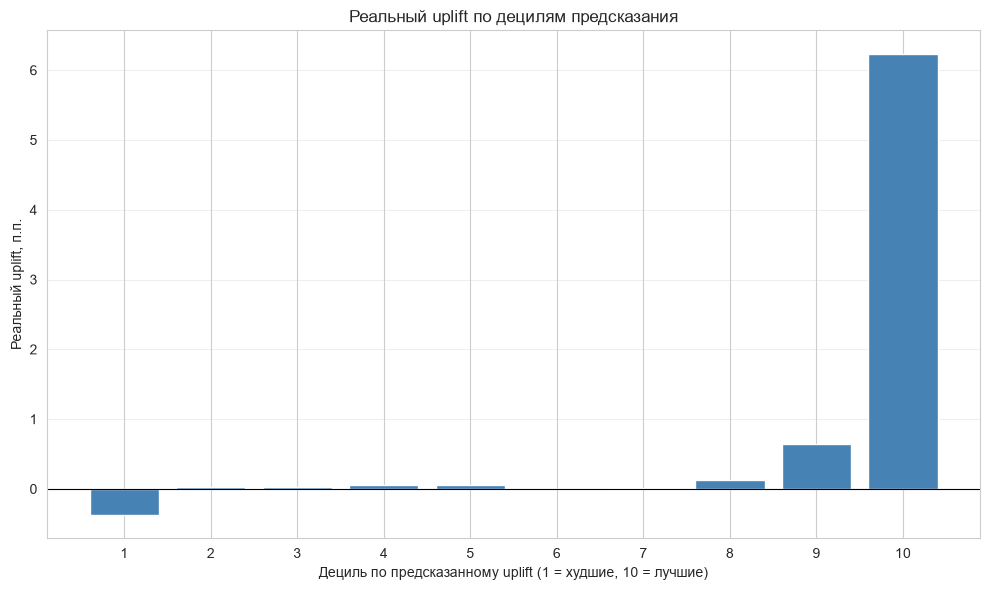

   decile  uplift_actual        n
0       0      -0.003755  55935.0
1       1       0.000225  56854.0
2       2       0.000199  55656.0
3       3       0.000615  55672.0
4       4       0.000547  56079.0
5       5       0.000050  55319.0
6       6       0.000185  55995.0
7       7       0.001323  55837.0
8       8       0.006459  55918.0
9       9       0.062381  55919.0


In [10]:
df_val = pd.DataFrame({
    'uplift_pred': uplift_sm,
    'visit': y_val.values,
    'treatment': treat_val.values
})

df_val['decile'] = pd.qcut(df_val['uplift_pred'], 10, labels=False, duplicates='drop')

decile_stats = df_val.groupby('decile').apply(
    lambda g: pd.Series({
        'uplift_actual': g[g['treatment']==1]['visit'].mean() - g[g['treatment']==0]['visit'].mean(),
        'n': len(g)
    })
).reset_index()

plt.figure(figsize=(10, 6))
plt.bar(decile_stats['decile'] + 1, decile_stats['uplift_actual'] * 100, color='steelblue')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Дециль по предсказанному uplift (1 = худшие, 10 = лучшие)')
plt.ylabel('Реальный uplift, п.п.')
plt.title('Реальный uplift по децилям предсказания')
plt.xticks(range(1, 11))
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('assets/uplift_by_decile.png', dpi=150, bbox_inches='tight')
plt.show()

print(decile_stats)

## Результаты

**A/B-тест.** Visit rate: 3.84% в control, 4.83% в treatment. Абсолютный uplift 1 п.п., относительный 26%, p-value < 1e-170.

**Модель.** Qini AUC 0.093, Uplift@30% 2.86% — почти втрое выше среднего uplift по выборке.

**Децили.** Эффект сконцентрирован в топ-10%:
- дециль 10: +6.24 п.п.
- дециль 9: +0.65 п.п.
- децили 2–7: около нуля
- дециль 1: −0.38 п.п.

Первый дециль — сегмент, где реклама снижает вероятность visit. Такие пользователи не должны получать показы.

**Вывод.** Средний uplift по всей выборке обманчив: он держится на 10% аудитории. Uplift-модель позволяет таргетироваться именно на них, не тратя бюджет на остальных. На том же охвате топ-10% даёт примерно в 6 раз больше эффекта, чем случайный показ.